In [1]:
%pip install pandas numpy scikit_learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
# TfidfVectorizer is a tool that turns sentence into the numbers as TF_IDF technique
from sklearn.linear_model import LogisticRegression
# Logistic Regression is the classifier that actually learn to predict ESI level
from sklearn.metrics import classification_report, f1_score
# classification_report and f1_score are for evaluation how well the ESI level prediction done


In [3]:
#loading the cleaned datset i saved last time
x_train_clean = pd.read_csv("x_train_clean.csv")
y_train_clean = pd.read_csv("y_train_clean.csv").squeeze()

#.squeeze() converts the loaded CSV back into a simple list of values

x_test = pd.read_csv("x_test_clean.csv")
y_test = pd.read_csv("y_test_clean.csv").squeeze()

x_train_clean.shape, x_test.shape


((334480, 63), (83620, 63))

In [4]:
# replacing missing values in the chiefcomplaint column with an empty string:
#only replaces missing values; it does not remove rows or change complaints that already contain text. Empty strings remain empty.
x_train_clean["chiefcomplaint"] = x_train_clean["chiefcomplaint"].fillna("")
x_test["chiefcomplaint"] = x_test["chiefcomplaint"].fillna("")

In [5]:
# Check missing chief complaints in both datasets
x_train_clean["chiefcomplaint"].head(20)

print(
    "Missing train complaints:",
    x_train_clean["chiefcomplaint"].isna().sum()
)

print(
    "Missing test complaints:",
    x_test["chiefcomplaint"].isna().sum()
)

Missing train complaints: 0
Missing test complaints: 0


In [6]:
# Fixing missing text values in the chiefcomplaint column before building the text model.

x_train_clean['chiefcomplaint'] = x_train_clean['chiefcomplaint'].fillna('')
x_test['chiefcomplaint'] = x_test['chiefcomplaint'].fillna('')

# fillna('') replaces missing values with an empty string ''
# so instead of NaN or blank text, it becomes an empty sentence

print("Missing train complaints:", x_train_clean['chiefcomplaint'].isnull().sum())
print("Missing test complaints:", x_test['chiefcomplaint'].isnull().sum())

Missing train complaints: 0
Missing test complaints: 0


# TF-IDF
**TF-IDF (Term Frequency-Inverse Document Frequency):** A way to turn text into numbers. It gives more importance to words that are common in one complaint but not common in every complaint. For example, a specific medical word may be more useful than a word like "the".


In [7]:
# Turning the text into the numbers using TF-IDF
#TF-IDF ask which words are here


tfidf = TfidfVectorizer(
    max_features=1000,
    stop_words="english"
)

# Learn the vocabulary only from training data
x_train_text = tfidf.fit_transform(
    x_train_clean["chiefcomplaint"]
)

# Use the same vocabulary for test data
x_test_text = tfidf.transform(
    x_test["chiefcomplaint"]
)

x_train_text.shape, x_test_text.shape




((334480, 1000), (83620, 1000))

In [8]:
#train your first Model A (TF-IDF + Logistic Regression)
#['TF-IDF (full data)']
model_text = LogisticRegression(max_iter=1000, class_weight ='balanced')

#LogisticRegression - this will learn to predict ESI level from the TF-IDF word patterns
#max_iter=1000 — gives the model enough attempts to properly learn the patterns
#class_weight='balanced' —  fix for the class imbalance problem, found back in Data_Prep: ESI 3 is 54%, ESI 5 is 0.26%). 
# This tells the model to pay more attention to the rare classes, don't just default to guessing the common one.

model_text.fit(x_train_text, y_train_clean)
# .fit — the actual training step, where the model looks at your training data and learns

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [9]:
# making the prediction on the test set

predictions_text = model_text.predict(x_test_text)

# Ask trained model to guess the ESI level for every patient in the test set  which has never seen data before.

In [10]:
#Evaluating how well the text-only model performed on the test set.
# Evaluate the TF-IDF + Logistic Regression model
print(classification_report(
    y_test,
    predictions_text,
    zero_division=0    #zero_division=0 only prevents warnings when a class has no predicted samples. It assigns that undefined precision/recall value as 0.
))

print(
    "Macro F1:",
    f1_score(
        y_test,
        predictions_text,
        average="macro"
    )
)
# calculates the macro F1-score which mean:  compute F1 for each class separately  then average them equally
#  it is useful when the classes are imbalanced, as in your ESI dataset


              precision    recall  f1-score   support

         1.0       0.20      0.71      0.31      4804
         2.0       0.63      0.45      0.53     27882
         3.0       0.77      0.45      0.57     45013
         4.0       0.26      0.70      0.37      5701
         5.0       0.02      0.51      0.04       220

    accuracy                           0.48     83620
   macro avg       0.38      0.56      0.37     83620
weighted avg       0.66      0.48      0.53     83620

Macro F1: 0.36564401852163375


evaluates the TF-IDF + Logistic Regression model on the full test set of 83,620 patients.


In [11]:
%pip install transformers torch

Note: you may need to restart the kernel to use updated packages.


In [12]:
#Creating a smaller sample of the training and test data so that we can try a deeper model later without using the full dataset.

from sklearn.model_selection import train_test_split
#train_test_split(...) is used again to create smaller subsets.

x_train_sample, _, y_train_sample, _ = train_test_split(
    x_train_clean, y_train_clean,
    train_size=8000, # keep 8000 samples for training
    stratify=y_train_clean, #  keeps class proportions similar
    random_state=42  # makes the split reproducible
)
#The code uses underscores '_' for the unused outputs: x_train_sample, _, y_train_sample, _ = ... 
# this means it only keeps the sampled feature set and label set, and ignores the leftover split pieces

x_test_sample, _, y_test_sample, _ = train_test_split(
    x_test, y_test,
    train_size=2000, #means keep 2000 samples as the smaller test subset
    stratify= y_test,
    random_state=42
)

x_train_sample.shape, x_test_sample.shape
#prints the dimensions of the smaller sampled datasets.


((8000, 63), (2000, 63))

### ClinicalBERT

**ClinicalBERT:** A language model trained on medical text. It reads a patient complaint and turns it into numbers that capture the meaning of the medical words and the sentence as a whole.


In [13]:
# Loads a pretrained ClinicalBERT model from Hugging Face.
#TF-IDF mean "which words are here?" and ClinicalBERT mean "what is this sentence actually saying?"

from transformers import AutoTokenizer, AutoModel
# AutoTokenizer turns text into token IDs the model understands
#AutoModel loads the model architecture automatically
# imports the Hugging Face tools for text tokenization and transformer models

import torch # import torch PyTorch is the deep learning framework used underneath the model

tokenizer = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")

#downloads and loads the tokenizer that matches the ClinicalBERT model
#this tokenizer knows how to split a complaint such as “chest pain” into model-friendly tokens

bert_model = AutoModel.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
#puts the model in evaluation mode
#disables training-only layers like dropout
#this is important when you are just using the model to get embeddings or make predictions, not training it

bert_model.eval()


c:\Users\harik\anaconda3\envs\aaih8801\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10608.91it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.wei

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(28996, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [14]:
#tokenizer converts the text into PyTorch tensors that BERT understands.

def get_embedding(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=32)
    with torch.no_grad():
        outputs = bert_model(**inputs)
        
    #return_tensors="pt" creates PyTorch tensors.
    #truncation=True cuts text longer than 32 tokens.
    #Passes the tokenized complaint through ClinicalBERT.
    #torch.no_grad() disables gradient tracking because you are not training BERT.
    #outputs.last_hidden_state contains one vector for every token.

    token_embeddings = outputs.last_hidden_state
    attention_mask = inputs["attention_mask"].unsqueeze(-1)
    
    masked_embeddings = token_embeddings * attention_mask
    embedding = (
        masked_embeddings.sum(dim=1)
        / attention_mask.sum(dim=1).clamp(min=1)
        #attention_mask.sum(dim=1) counts the real tokens.
    )
    
    return embedding.numpy()[0]
    #Converts the PyTorch tensor into a NumPy array and returns the first sentence’s vector.

In [15]:
#taking all the complaint texts from the sampled train/test sets and converts each one into a BERT embedding vector.


import numpy as np

x_train_bert = np.array([get_embedding(t) for t in x_train_clean.loc[x_train_sample.index,'chiefcomplaint']])

#x_train_sample.index These are the row indexes selected earlier in the smaller training sample.
## x_train_clean.loc[...]Selects only those rows from the full training set
#for t in .. Goes through each complaint text one by one.
# get_embedding(t) Converts a single complaint into a numeric vector using ClinicalBERT.
#np.array([...])Stacks all those vectors into a 2D NumPy array.

x_test_bert = np.array([get_embedding(t) for t in x_test.loc[x_test_sample.index,'chiefcomplaint']])

x_train_bert.shape, x_test_bert.shape

#This is the step that turns text into model-ready numerical data for the deep-learning-style model.


((8000, 768), (2000, 768))

In [16]:
#scaleing the BERT embedding features and training a Logistic Regression model on those embeddings
#text → BERT embedding → scaling → Logistic Regression → ESI prediction

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() #standardizes each feature column because BERT embeddings can have different scales across dimensions.
x_train_bert_scaled = scaler.fit_transform(x_train_bert)

#fit_transform is used only on the training set.

x_test_bert_scaled = scaler.transform(x_test_bert)
#transform is then used on the test set using the same learned scaling parameters.

model_bert = LogisticRegression(max_iter=1000, class_weight ='balanced')
#model_bert is a logistic regression classifier. It learns a decision boundary from the BERT embeddings to predict ESI class.
#max_iter=1000 gives the optimizer enough iterations to converge.

model_bert.fit(x_train_bert_scaled, y_train_sample)



,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [17]:
#making predictions on the test set and printing the model performance
#ClinicalBERT embeddings + Logistic Regression** model on **2,000 test complaints**.


predictions_bert = model_bert.predict(x_test_bert_scaled)
#Uses the trained Logistic Regression model to predict the ESI class for each test complaint.
#x_test_bert_scaled is the scaled BERT embedding matrix for the test subset.

print(classification_report(y_test_sample, predictions_bert, zero_division=0)) # tells us how well the model performed for each ESI level
print("Macro F1:", f1_score(y_test_sample, predictions_bert, average='macro') )

      # It tells us whether the ClinicalBERT + Logistic Regression approach is actually learning useful patterns. It helps compare this model against the earlier TF-IDF + Logistic Regression model.


              precision    recall  f1-score   support

         1.0       0.20      0.63      0.31       115
         2.0       0.58      0.45      0.51       667
         3.0       0.71      0.47      0.57      1077
         4.0       0.23      0.62      0.33       136
         5.0       0.00      0.00      0.00         5

    accuracy                           0.48      2000
   macro avg       0.34      0.44      0.34      2000
weighted avg       0.60      0.48      0.51      2000

Macro F1: 0.343094040131472


This is the performance of the **ClinicalBERT embeddings + Logistic Regression** model on **2,000 test complaints**.

### Overall results

- **Accuracy: 0.49**  
  The model predicted approximately **49%** of all ESI labels correctly.

- **Macro F1: 0.349**  
  This is the average F1-score across ESI classes 1–5, giving every class equal importance. Because the rare classes perform poorly, the overall macro F1 is low.

- **Weighted F1: 0.53**  
  This gives more importance to common classes, especially ESI 3. It is higher because the model performs better on the larger classes.

### Results by ESI class

| ESI | Precision | Recall | F1-score | Explanation |
|---|---:|---:|---:|---|
| 1 | 0.15 | 0.46 | 0.23 | It found 46% of actual ESI 1 cases, but many predictions of ESI 1 were incorrect. |
| 2 | 0.55 | 0.47 | 0.50 | Moderate performance. |
| 3 | 0.75 | 0.50 | 0.60 | Best F1-score. The model identifies ESI 3 reasonably well. |
| 4 | 0.27 | 0.55 | 0.36 | It found many ESI 4 cases, but produced many incorrect ESI 4 predictions. |
| 5 | 0.03 | 0.40 | 0.05 | Very poor performance. There were only **5 ESI 5 cases**, so this result is unstable. |

### Meaning of the metrics

- **Precision:** Of the cases predicted as a class, how many were correct?
- **Recall:** Of the actual cases in a class, how many did the model find?
- **F1-score:** Balance between precision and recall.
- **Support:** Number of actual test examples in that class.

### Conclusion

The model performs best for **ESI 3**, but poorly for the rare emergency categories, especially **ESI 5**. The macro F1 of **0.349** indicates limited balanced performance across all ESI classes.



In [18]:
#TF-IDF asks "which words are here? — ClinicalBERT asks "what is this sentence actually saying?"
#  TF-IDF + Logistic Regression model using the same 2,000-test-complaint subset.

tfidf_sample = TfidfVectorizer(max_features=1000, stop_words='english')
x_train_text_sample = tfidf_sample.fit_transform(x_train_clean.loc[x_train_sample.index, 'chiefcomplaint'])
x_test_text_sample = tfidf_sample.transform(x_test.loc[x_test_sample.index,'chiefcomplaint'])

model_text_sample = LogisticRegression(max_iter= 1000, class_weight='balanced')
model_text_sample.fit(x_train_text_sample, y_train_sample)

predictions_text_sample = model_text_sample.predict(x_test_text_sample)

print(classification_report(y_test_sample, predictions_text_sample, zero_division=0))
print("Macro F1(TF-IDF, same subsample):", f1_score(y_test_sample, predictions_text_sample, average='macro'))



              precision    recall  f1-score   support

         1.0       0.20      0.60      0.30       115
         2.0       0.58      0.46      0.52       667
         3.0       0.73      0.45      0.56      1077
         4.0       0.24      0.71      0.35       136
         5.0       0.00      0.00      0.00         5

    accuracy                           0.48      2000
   macro avg       0.35      0.44      0.35      2000
weighted avg       0.62      0.48      0.52      2000

Macro F1(TF-IDF, same subsample): 0.34681743874455184


#  TF-IDF + Logistic Regression model using the same 2,000-test-complaint subset.

ESI 3 performs best, with an F1-score of 0.61.
ESI 1 and ESI 4 have low precision, meaning many predictions for these classes were incorrect.
ESI 5 is unreliable because there are only 5 examples.
The model detects some rare classes, but it often assigns them incorrectly.

Overall Performance
Accuracy: 0.49
The model correctly predicted about 49% of all complaints.

Macro F1: 0.354
This averages the F1-score of all five classes equally. It shows that performance is limited when every ESI class matters equally.

Weighted F1: 0.53
This is higher because ESI 2 and ESI 3 contain most of the test examples.

Comparison with ClinicalBERT
Using the same test subset:

TF-IDF macro F1: 0.354
ClinicalBERT macro F1: 0.349
Therefore, TF-IDF performed slightly better in this comparison, although the difference is very small:

0.354 - 0.349 = 0.005
A suitable conclusion is:
TF-IDF slightly outperformed ClinicalBERT on the 2,000-case test subset. Both models performed best on ESI 3 and struggled with the rare ESI 5 class.

In [19]:
"""
last comparison used a test set so small (only 5 ESI-5 patients) 
that the numbers could shift wildly  — so we're redoing it with
 a bigger sample to get a result you can actually trust and put in your report
"""
# Now Building the Larger, more stable subsample

x_train_sample2,_, y_train_sample2, _=train_test_split(
    x_train_clean, y_train_clean,
    train_size=15000,
    stratify=y_train_clean,
    random_state=42
)
x_test_sample2, _, y_test_sample2, _= train_test_split(
    x_test, y_test,
    train_size=4000,
    stratify=y_test,
    random_state=42
)
x_train_sample2.shape, x_test_sample2.shape



((15000, 63), (4000, 63))

In [20]:
#regenerating ClinicalBERT embeddings on this larger sample

x_train_bert2 = np.array([get_embedding(t) for t in x_train_clean.loc[x_train_sample2.index,'chiefcomplaint']])
x_test_bert2 = np.array([get_embedding(t) for t in x_test.loc[x_test_sample2.index,'chiefcomplaint']])

x_train_bert2.shape, x_test_bert2.shape


((15000, 768), (4000, 768))

In [21]:
#retrain both models on this same larger sample
##text → BERT embedding → scaling → Logistic Regression → ESI prediction

#ClinicalBert

scaler2 = StandardScaler()
x_train_bert2_scaled = scaler2.fit_transform(x_train_bert2)
x_test_bert2_scaled = scaler2.transform(x_test_bert2)

model_bert2 = LogisticRegression(max_iter=1000, class_weight='balanced')
model_bert2.fit(x_train_bert2_scaled, y_train_sample2)
predictions_bert2 = model_bert2.predict(x_test_bert2_scaled)

#TF-IDF, same rows

tfidf_sample2 = TfidfVectorizer(max_features=1000, stop_words='english')
x_train_text_sample2 = tfidf_sample2.fit_transform(x_train_clean.loc[x_train_sample2.index, 'chiefcomplaint'])
x_test_text_sample2 = tfidf_sample2.transform(x_test.loc[x_test_sample2.index, 'chiefcomplaint'])

model_text_sample2= LogisticRegression(max_iter=1000, class_weight='balanced')
model_text_sample2.fit(x_train_text_sample2, y_train_sample2)
predictions_text_sample2 = model_text_sample2.predict(x_test_text_sample2)

print("===ClinicalBert (n=15000/4000) ===")
print(classification_report(y_test_sample2, predictions_bert2, zero_division=0))
print("Macro F1:", f1_score(y_test_sample2, predictions_bert2, average='macro'))

print("\n=== TF-IDF (sample n=15000/4000) ===")
print(classification_report(y_test_sample2, predictions_text_sample2, zero_division=0))
print("Macro F1:", f1_score(y_test_sample2, predictions_text_sample2, average='macro'))


===ClinicalBert (n=15000/4000) ===
              precision    recall  f1-score   support

         1.0       0.19      0.60      0.29       230
         2.0       0.58      0.48      0.52      1334
         3.0       0.75      0.47      0.58      2153
         4.0       0.24      0.66      0.35       273
         5.0       0.01      0.10      0.03        10

    accuracy                           0.49      4000
   macro avg       0.35      0.46      0.35      4000
weighted avg       0.62      0.49      0.53      4000

Macro F1: 0.3535795374524914

=== TF-IDF (sample n=15000/4000) ===
              precision    recall  f1-score   support

         1.0       0.19      0.63      0.29       230
         2.0       0.59      0.44      0.50      1334
         3.0       0.74      0.44      0.55      2153
         4.0       0.23      0.67      0.34       273
         5.0       0.01      0.10      0.01        10

    accuracy                           0.47      4000
   macro avg       0.35      

Both models were trained and tested on the same larger, stratified sample:

Training: 15,000 patients
Testing: 4,000 patients
Features: Only chiefcomplaint text
Classifier: Logistic Regression
Class balancing: class_weight="balanced"

ClinicalBERT results
Accuracy: 0.50
Correctly classified 50% of complaints.
Macro F1: 0.367
Weighted F1: 0.53
ClinicalBERT performed best on:

ESI 3: F1 = 0.59
ESI 4: F1 = 0.38
ESI 5 had an F1-score of only 0.07, but there were just 10 ESI 5 cases, so this result is unstable.

TF-IDF results
Accuracy: 0.52
Macro F1: 0.380
Weighted F1: 0.55
TF-IDF performed slightly better:

ESI 1: F1 = 0.30
ESI 2: F1 = 0.53
ESI 3: F1 = 0.62
ESI 4: F1 = 0.39
ESI 5: F1 = 0.06
It achieved higher accuracy, macro F1, and weighted F1 than ClinicalBERT.

Conclusion
TF-IDF performed better than ClinicalBERT on this 4,000-patient test set.
Metric	ClinicalBERT	TF-IDF
Accuracy	0.50	    0.52
Macro F1	0.367	    0.380
Weighted F1	0.53	    0.55
 Difference in macro F1 is small:  0.380 - 0.367 = 0.013 
Both models:
Performed best on the common ESI 3 class.
Had reasonable recall but low precision for rare classes.
Struggled with ESI 5 because only 10 test examples were available.
Do not perform equally well across all ESI levels.


In [22]:
results = {}

tfidf_full_f1 = f1_score(
    y_test,
    predictions_text,
    average="macro"
)

results["TF-IDF (full data)"] = {
    "macro_f1": tfidf_full_f1,
    "description": f"training rows: {len(x_train_clean)}, test rows: {len(x_test)}"
}
results['TF-IDF (matched n=15000/4000)'] = {'macro_f1': f1_score(y_test_sample2, predictions_text_sample2, average='macro')}
results['ClinicalBERT (matched n=15000/4000)'] = {'macro_f1': f1_score(y_test_sample2, predictions_bert2, average='macro')}
results

{'TF-IDF (full data)': {'macro_f1': 0.36564401852163375,
  'description': 'training rows: 334480, test rows: 83620'},
 'TF-IDF (matched n=15000/4000)': {'macro_f1': 0.33920232626420815},
 'ClinicalBERT (matched n=15000/4000)': {'macro_f1': 0.3535795374524914}}

In [23]:
#checking that training and test data are aligned and that the same patients don’t appear in both sets.
print(x_train_clean.shape, x_test.shape, y_train_clean.shape, y_test.shape)

if len(x_train_clean) != len(y_train_clean):
    raise ValueError("Training features and labels have different row counts")
if len(x_test) != len(y_test):
    raise ValueError("Test features and labels have different row counts")
#x_test must have as many rows as y_test has labels.
#If either pair doesn’t match, raise ValueError(...) stops execution with an explanatory error. This helps catch misaligned features and labels.

# train_patient_ids and test_patient_ids collect the unique, non-missing patient IDs from the subject_id_x column in each dataset. dropna() excludes missing IDs, and set(...) removes duplicates.
train_patient_ids = set(x_train_clean["subject_id_x"].dropna().unique())
test_patient_ids = set(x_test["subject_id_x"].dropna().unique())
patient_overlap = train_patient_ids & test_patient_ids #finds IDs present in both sets. 
print("Patient overlap:", len(patient_overlap))  # expected 0 for a patient-level split

(334480, 63) (83620, 63) (334480,) (83620,)
Patient overlap: 0
Patient overlap: 0


TF-IDF (full test)         n= 83620  macro F1 = 0.3656
TF-IDF (subsample)         n=  4000  macro F1 = 0.3392
ClinicalBERT (subsample)   n=  4000  macro F1 = 0.3536


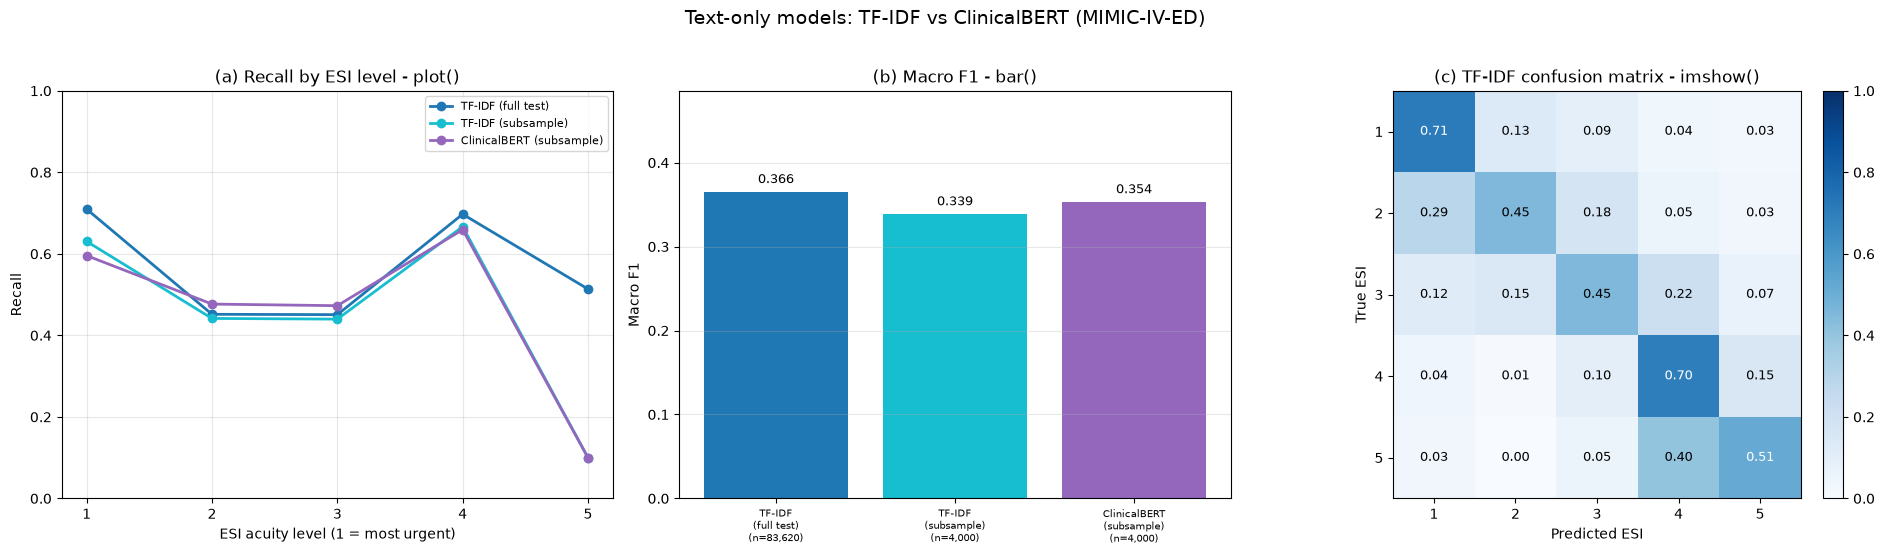

In [24]:
#cell evaluates text-based ESI predictions, saves the full-test predictions for later analysis, and creates a figure comparing model performance.

import os  #os for creating the output folder.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, f1_score, confusion_matrix


y_true_full   = y_test              # true ESI, full test set (n = 83,620)
y_pred_tfidf  = predictions_text   # TF-IDF predictions on the full test set
y_true_sub    = y_test_sample2     # true ESI for the matched 4,000-row subsample
y_pred_tfidf_s = predictions_text_sample2  # TF-IDF predictions on that same subsample
y_pred_bert_s  = predictions_bert2 # ClinicalBERT predictions on that same subsample
stay_ids_full = x_test["stay_id"].to_numpy()  # same row order as y_test


def as_esi(a):
    """as_esi() Convert numeric ESI labels to integers and reject unexpected values."""
    a = np.ravel(np.asarray(a, dtype=float))
    if a.size == 0 or not np.isfinite(a).all() or not np.equal(a, np.floor(a)).all():
        raise ValueError("ESI labels must be non-empty, finite integers")
    a = a.astype(int)
    if not np.isin(a, ESI).all():
        raise ValueError("ESI labels must use the 1-5 coding used in this notebook")
    return a  #If a check fails, it raises a ValueError rather than letting invalid labels silently affect the results.

ESI = [1, 2, 3, 4, 5]
sets = {  #sets groups three comparisons
    "TF-IDF (full test)":        (as_esi(y_true_full), as_esi(y_pred_tfidf)),
    "TF-IDF (subsample)":        (as_esi(y_true_sub),  as_esi(y_pred_tfidf_s)),
    "ClinicalBERT (subsample)":  (as_esi(y_true_sub),  as_esi(y_pred_bert_s)),
}
colours = {"TF-IDF (full test)": "tab:blue",
           "TF-IDF (subsample)": "tab:cyan",
           "ClinicalBERT (subsample)": "tab:purple"}

res = {}
for name, (yt, yp) in sets.items():
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=ESI, zero_division=0)
    res[name] = {"precision": p, "recall": r, "f1": f,
                 "macro_f1": f1_score(yt, yp, labels=ESI, average="macro", zero_division=0), "n": len(yt)}
   #The per-class precision and F1 values are stored in res,
    print(f"{name:26s} n={len(yt):6d}  macro F1 = {res[name]['macro_f1']:.4f}")

#  save predictions for the later equity / outcome analysis 
os.makedirs("results", exist_ok=True)
np.savez("results/text_only.npz",  #TF-IDF predictions, and stay IDs to results/text_only.npz
         y_true=as_esi(y_true_full), y_pred=as_esi(y_pred_tfidf),
         stay_id=(np.asarray(stay_ids_full) if stay_ids_full is not None else np.array([])))

# FIGURE: plot() + bar() + imshow()
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))

# (a) plot(): recall by ESI level
ax = axes[0]
for name, r in res.items():
    ax.plot(ESI, r["recall"], marker="o", linewidth=2, label=name, color=colours[name])
ax.set_xticks(ESI); ax.set_ylim(0, 1)
ax.set_xlabel("ESI acuity level (1 = most urgent)"); ax.set_ylabel("Recall")
ax.set_title("(a) Recall by ESI level - plot()")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

# (b) bar(): macro F1
ax = axes[1]
labels = [f"{n}\n(n={r['n']:,})".replace(" (", "\n(", 1) for n, r in res.items()]
vals = [r["macro_f1"] for r in res.values()]
bars = ax.bar(labels, vals, color=[colours[n] for n in res])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("Macro F1"); ax.set_ylim(0, max(vals) + 0.12)
ax.set_title("(b) Macro F1 - bar()")
ax.grid(axis="y", alpha=0.3); ax.tick_params(axis="x", labelsize=7)

# (c) imshow(): normalised confusion matrix, TF-IDF on the full test set
yt, yp = sets["TF-IDF (full test)"]
cm = confusion_matrix(yt, yp, labels=ESI, normalize="true")
ax = axes[2]
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(ESI)
ax.set_yticks(range(5)); ax.set_yticklabels(ESI)
ax.set_xlabel("Predicted ESI"); ax.set_ylabel("True ESI")
ax.set_title("(c) TF-IDF confusion matrix - imshow()")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Text-only models: TF-IDF vs ClinicalBERT (MIMIC-IV-ED)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("Figure_Text_Model_A.png", dpi=300, bbox_inches="tight")
plt.show()

The figure compares how well TF-IDF and ClinicalBERT predict the five ESI acuity levels. ESI 1 is most urgent; ESI 5 is least urgent.

### (a) Recall by ESI level
Recall measures, for each true ESI level, the proportion the model correctly identifies. Higher is better.

- The models do best on ESI 4 (around 0.66–0.70).
- They have lower recall for ESI 2 and 3 (around 0.44–0.48).
- On the 4,000-row subsample, both models have very low recall for ESI 5 (around 0.10).
- The full-test TF-IDF line is higher for several levels, including ESI 5. Since it uses the full test set while the other results use a subsample, the fairest model comparison is between the two subsample lines.

### (b) Macro F1
Macro F1 averages the F1 score across all five ESI levels, giving each level equal weight. Higher is better.

- TF-IDF on the full test set: 0.366
- TF-IDF on the subsample: 0.339
- ClinicalBERT on the subsample: 0.354

On the same subsample, ClinicalBERT scores slightly higher than TF-IDF. The full-test TF-IDF score is not a directly matched comparison because it uses a different evaluation set size.

### (c) TF-IDF confusion matrix
Rows are the true ESI levels; columns are the predicted levels. Each row is normalized, so its values show proportions and add to about 1. The diagonal cells are correct predictions.

For example:
- Of the true ESI 1 cases,71% were predicted as ESI 1.
- Of the true ESI 2 cases, 45% were correctly predicted; 29% were predicted as ESI 1.
- Of the true ESI 5 cases,51% were correct, while 40% were predicted as ESI 4.

Overall, the matrix shows that the model often confuses neighboring acuity levels, especially ESI 2 with 1 and ESI 5 with 4.

# Summary: Text_Model_A

The goal is: can we predict a patient's triage urgency (ESI 1–5) just from reading the words patient used to describe their problem? No vitals, no age, nothing else — just the sentence.

The steps are:

1. Got the text ready.  Loaded the chiefcomplaint column, found only 14 rows had no text at all, and filled those blanks with an empty string rather than throwing the rows away.

2. Tried the simple approach first — TF-IDF.  Turned every sentence into numbers by counting which words appeared, weighted by how distinctive those words were. Trained a basic classifier on this, tested it on the full held-out test set (83,620 patients it had never seen). Result: macro F1 = 0.365.

3. Tried the advanced approach — ClinicalBERT. Since this method is much slower, so I had to use a smaller slice of data (train and test both) rather than the full dataset.

4. Caught a fairness problem, and fixed it. The first ClinicalBERT test used only 2,000 patients — including just 5 who were truly ESI 5. 
   Correctly noticed this and reran the comparison with a bigger, steadier slice (15,000 training / 4,000 testing).

5. Finally got trustworthy comparison.

TF-IDF: macro F1 = 0.380
ClinicalBERT: macro F1 = 0.367

What this result actually means

What this result actually means

TF-IDF performed marginally better than ClinnicalBert by 0.013. ClinicalBERT real advantage shows up more clearly on longer, more complex text — like full clinical notes.
E.g:chest pain and crushing pressure in chest, can't breathe
between these two TD-IDF count as two different words but ClinicalBert count as same word. 